# Step 4b: Baseline Aggregation across Seeds

The training-side numbers of the clean baseline are produced here from the files written by the five training runs of Step 4a: the paired comparison of test RMSE across seeds, the label-noise decomposition, the training cost, and the per-regime comparison with Benjamini-Hochberg correction. Nothing is re-trained and nothing is entered by hand, so these numbers can be reproduced from the released artefacts.

The clean-baseline table of the paper, including the gross-failure rate, is produced by Step 5.0 from the reloaded checkpoints. The figures in this notebook are diagnostic views of the training runs and are not figures of the paper.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR = 'data'
RESULTS_DIR = 'results'
CKPT_DIR = 'checkpoints'

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS = [0, 1, 2, 3, 4]

# One colour per model for the diagnostic figures below (colourblind-safe)
COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD
# ==========================================
with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = json.load(open(os.path.join(DATA_DIR, 'catalog_meta.json')))['label_noise_floor_K']   # Step 1

summaries, histories = [], []
for m in MODELS:
    for s in SEEDS:
        with open(os.path.join(RESULTS_DIR, f'summary_{m}_seed{s}.json')) as f:
            summaries.append(json.load(f))
        histories.append(pd.read_csv(os.path.join(RESULTS_DIR, f'history_{m}_seed{s}.csv')))

hist = pd.concat(histories, ignore_index=True)

print(f'Loaded {len(summaries)} runs, {len(hist):,} epoch records.')
print(f'  Kelvin conversion factor : {TEFF_RANGE:.4f} K')
print(f'  Label-noise floor        : {NOISE_FLOOR:.1f} K')

n_ckpt = len([f for f in os.listdir(CKPT_DIR) if f.endswith('.pth')]) \
         if os.path.isdir(CKPT_DIR) else 0
print(f'  Checkpoints present      : {n_ckpt} (needed by Step 5, unused here)')

Loaded 10 runs, 721 epoch records.
  Kelvin conversion factor : 5498.9161 K
  Label-noise floor        : 47.9 K
  Checkpoints present      : 10 (needed by Step 5, unused here)


## 1. Headline comparison

Both models see the same data split within a seed, so the five observations form matched pairs; a paired design removes the seed-to-seed variation common to both and tests only the difference between architectures.

In [2]:
runs = pd.DataFrame([{
    'model': s['model'], 'seed': s['seed'],
    'n_params': s['n_params'],
    'epochs': s['epochs_run'], 'best_epoch': s['best_epoch'],
    'val_rmse_K': s['best_val_rmse_kelvin'],
    'test_rmse_K': s['test_rmse_kelvin'],
    'test_mae_K': s['test_mae_kelvin'],
    'test_bias_K': s['test_bias_kelvin'],
    'test_r2': s['test_r2'],
    'min_per_epoch': s['mean_epoch_time_s'] / 60,
    'total_hours': s['total_time_s'] / 3600,
} for s in summaries]).sort_values(['model', 'seed']).reset_index(drop=True)

print('Per-seed results:')
display(runs.round(4))

METRICS = ['test_rmse_K', 'test_mae_K', 'test_bias_K', 'test_r2',
           'epochs', 'best_epoch', 'min_per_epoch', 'total_hours']

print('\nAggregate over seeds:')
display(runs.groupby('model')[METRICS].agg(['mean', 'std']).round(4).T)


def paired(metric):
    """Paired comparison of Conv-Attn against Conv-Pool across seeds."""
    p = runs.loc[runs.model == 'Conv-Pool'].sort_values('seed')[metric].values
    a = runs.loc[runs.model == 'Conv-Attn'].sort_values('seed')[metric].values
    d = a - p
    tt = stats.ttest_rel(a, p)
    ww = stats.wilcoxon(a, p) if np.any(d != 0) else None
    lo, hi = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
    return {'metric': metric,
            'Conv-Pool': p.mean(), 'Conv-Pool_sd': p.std(ddof=1),
            'Conv-Attn': a.mean(), 'Conv-Attn_sd': a.std(ddof=1),
            'diff': d.mean(), 'diff_sd': d.std(ddof=1),
            'ci_lo': lo, 'ci_hi': hi,
            't_p': tt.pvalue,
            'wilcoxon_p': ww.pvalue if ww is not None else np.nan}


tests = pd.DataFrame([paired(m) for m in METRICS]).set_index('metric')
print('\nPaired comparison (Conv-Attn minus Conv-Pool):')
display(tests.round(4))

r = tests.loc['test_rmse_K']
print('\n' + '=' * 72)
print(f"Conv-Pool {r['Conv-Pool']:.2f} +/- {r['Conv-Pool_sd']:.2f} K   vs   "
      f"Conv-Attn {r['Conv-Attn']:.2f} +/- {r['Conv-Attn_sd']:.2f} K")
print(f"difference {r['diff']:+.2f} +/- {r['diff_sd']:.2f} K, "
      f"95% CI [{r['ci_lo']:+.2f}, {r['ci_hi']:+.2f}], "
      f"paired t p = {r['t_p']:.3f}, Wilcoxon p = {r['wilcoxon_p']:.3f}")
print(f"-> statistically "
      f"{'indistinguishable' if r['t_p'] > 0.05 else 'distinguishable'} on clean data")
print('=' * 72)

Per-seed results:


,model,seed,n_params,epochs,best_epoch,val_rmse_K,test_rmse_K,test_mae_K,test_bias_K,test_r2,min_per_epoch,total_hours
0,Conv-Attn,0,540161,78,63,84.0139,81.5801,56.8716,-5.0526,0.9928,1.2471,1.6212
1,Conv-Attn,1,540161,77,62,84.7574,81.7054,57.5162,-8.1490,0.9928,1.2073,1.5493
2,Conv-Attn,2,540161,82,67,84.5008,81.5436,56.9570,-5.5175,0.9928,1.2568,1.7176
3,Conv-Attn,3,540161,79,64,83.1101,81.0674,57.1238,1.4169,0.9929,1.2430,1.6366
4,Conv-Attn,4,540161,77,62,84.4368,82.7435,58.1304,-3.6232,0.9926,1.2714,1.6316
5,Conv-Pool,0,537857,67,52,84.1893,81.5825,57.2408,-4.1921,0.9928,0.7239,0.8083
6,Conv-Pool,1,537857,70,55,82.9224,80.5414,56.3357,-6.9869,0.9930,0.6941,0.8098
7,Conv-Pool,2,537857,67,52,84.3594,80.6031,56.5980,-5.1024,0.9930,0.7370,0.8230
8,Conv-Pool,3,537857,58,43,84.4681,81.4322,57.2112,-6.4240,0.9928,0.7178,0.6939
9,Conv-Pool,4,537857,66,51,84.5967,81.2057,56.5618,0.9887,0.9929,0.7348,0.8083



Aggregate over seeds:


model               Conv-Attn  Conv-Pool
test_rmse_K   mean    81.7280    81.0730
              std      0.6173     0.4769
test_mae_K    mean    57.3198    56.7895
              std      0.5164     0.4111
test_bias_K   mean    -4.1851    -4.3433
              std      3.5334     3.1760
test_r2       mean     0.9928     0.9929
              std      0.0001     0.0001
epochs        mean    78.6000    65.6000
              std      2.0736     4.5056
best_epoch    mean    63.6000    50.6000
              std      2.0736     4.5056
min_per_epoch mean     1.2451     0.7215
              std      0.0238     0.0172
total_hours   mean     1.6313     0.7887
              std      0.0598     0.0533


Paired comparison (Conv-Attn minus Conv-Pool):


,Conv-Pool,Conv-Pool_sd,Conv-Attn,Conv-Attn_sd,diff,diff_sd,ci_lo,ci_hi,t_p,wilcoxon_p
metric,,,,,,,,,,
test_rmse_K,81.0730,0.4769,81.7280,0.6173,0.6550,0.8050,-0.3445,1.6545,0.1430,0.3125
test_mae_K,56.7895,0.4111,57.3198,0.5164,0.5303,0.8248,-0.4938,1.5544,0.2239,0.4375
test_bias_K,-4.3433,3.1760,-4.1851,3.5334,0.1583,4.6067,-5.5617,5.8782,0.9425,0.6250
test_r2,0.9929,0.0001,0.9928,0.0001,-0.0001,0.0001,-0.0003,0.0001,0.1433,0.3125
epochs,65.6000,4.5056,78.6000,2.0736,13.0000,5.2915,6.4297,19.5703,0.0054,0.0625
best_epoch,50.6000,4.5056,63.6000,2.0736,13.0000,5.2915,6.4297,19.5703,0.0054,0.0625
min_per_epoch,0.7215,0.0172,1.2451,0.0238,0.5236,0.0086,0.5129,0.5342,0.0000,0.0625
total_hours,0.7887,0.0533,1.6313,0.0598,0.8426,0.0784,0.7452,0.9400,0.0000,0.0625



Conv-Pool 81.07 +/- 0.48 K   vs   Conv-Attn 81.73 +/- 0.62 K
difference +0.66 +/- 0.80 K, 95% CI [-0.34, +1.65], paired t p = 0.143, Wilcoxon p = 0.312
-> statistically indistinguishable on clean data


## 2. Label-noise decomposition

The labels carry their own uncertainty, so the observed error decomposes as

$$\mathrm{RMSE}^2 = \underbrace{\mathbb{E}\big[(\hat{y}-y_{\text{true}})^2\big]}_{\text{model}} + \sigma^2_{\text{label}}$$

and no model can score below $\sigma_{\text{label}}$ against these labels. The ratio of the achieved RMSE to that floor states how much room is left.

In [3]:
noise = pd.DataFrame([{
    'model': m,
    'rmse_K': (r := runs.loc[runs.model == m, 'test_rmse_K'].mean()),
    'model_error_K': np.sqrt(r**2 - NOISE_FLOOR**2),
    'label_share_of_mse_%': 100 * NOISE_FLOOR**2 / r**2,
    'rmse_over_floor': r / NOISE_FLOOR,
} for m in MODELS]).set_index('model')

print(f'Label-noise floor: {NOISE_FLOOR:.1f} K')
display(noise.round(3))

Label-noise floor: 47.9 K


,rmse_K,model_error_K,label_share_of_mse_%,rmse_over_floor
model,,,,
Conv-Pool,81.073,65.411,34.905,1.693
Conv-Attn,81.728,66.221,34.348,1.706


## 3. Diagnostic figure: convergence across seeds

Median across the five seeds with an interquartile band. Median and IQR are preferred to mean and standard deviation because a single seed occasionally produces a validation spike an order of magnitude above the trend, which would dominate a mean-based band and hide the behaviour of the other four runs. The vertical axis is logarithmic for the same reason.

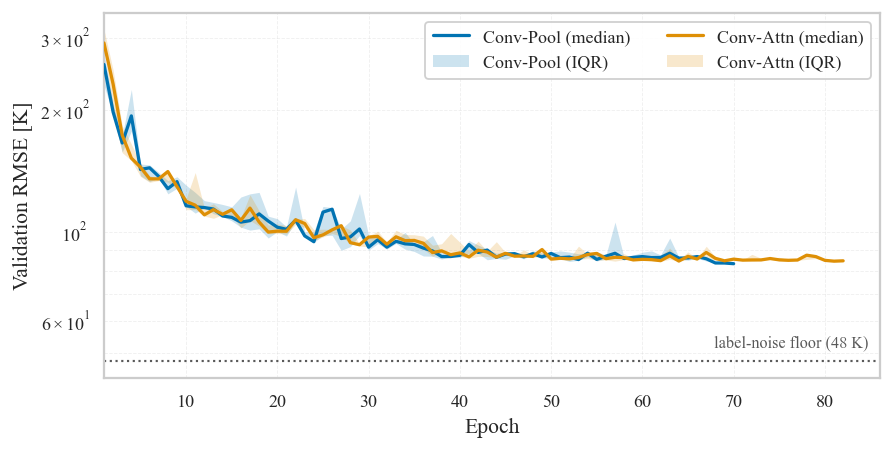

In [4]:
def stack_runs(model, column='val_rmse_kelvin'):
    """Return a (n_seeds, max_epochs) array, NaN-padded where a run stopped early."""
    sub = hist[hist.model == model]
    n_ep = int(sub['epoch'].max())
    mat = np.full((len(SEEDS), n_ep), np.nan)
    for i, s in enumerate(SEEDS):
        v = sub[sub.seed == s].sort_values('epoch')[column].values
        mat[i, :len(v)] = v
    return mat


fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.6))

for m in MODELS:
    mat = stack_runs(m)
    ep = np.arange(1, mat.shape[1] + 1)
    ax.plot(ep, np.nanmedian(mat, axis=0), color=COLORS[m], lw=1.8, label=f'{m} (median)', zorder=3)
    ax.fill_between(ep, np.nanpercentile(mat, 25, axis=0),
                    np.nanpercentile(mat, 75, axis=0),
                    color=COLORS[m], alpha=0.20, lw=0,
                    label=f'{m} (IQR)', zorder=2)

ax.axhline(NOISE_FLOOR, color='0.35', ls=':', lw=1.2, zorder=1)
ax.text(ax.get_xlim()[1] * 0.985, NOISE_FLOOR * 1.06,
        f'label-noise floor ({NOISE_FLOOR:.0f} K)',
        ha='right', va='bottom', fontsize=9, color='0.35')

ax.set_yscale('log')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation RMSE [K]')
ax.set_xlim(1, None)
ax.grid(True, which='both', ls='--', alpha=0.3, lw=0.5)
ax.legend(loc='upper right', framealpha=0.92, ncol=2)
plt.tight_layout()
plt.show()

## 4. Diagnostic figure: final accuracy and training cost

Five points per model rather than a box plot: with five observations a box plot implies more data than exists, and the individual seeds are the evidence. Lines join the paired seeds, so the sign of each pairwise difference is visible.

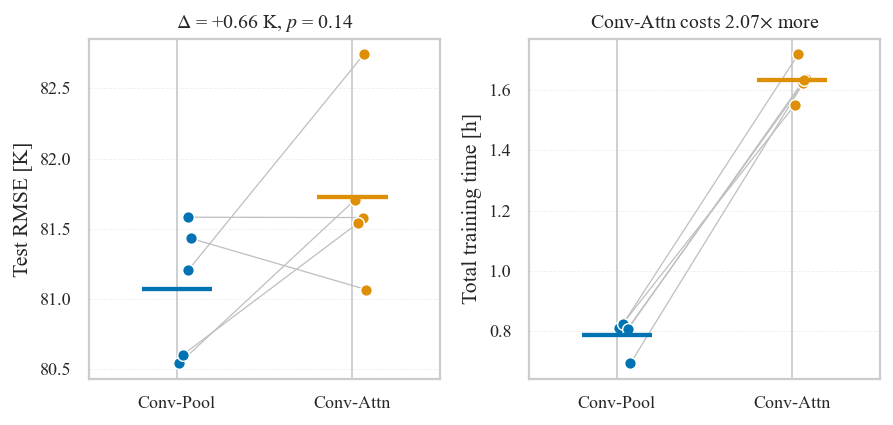

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))
jitter = np.random.RandomState(0).normal(0, 0.035, len(SEEDS))

for ax, metric, ylab in [
        (axes[0], 'test_rmse_K', 'Test RMSE [K]'),
        (axes[1], 'total_hours', 'Total training time [h]')]:

    vals = {m: runs.loc[runs.model == m].sort_values('seed')[metric].values for m in MODELS}

    for k in range(len(SEEDS)):                       # paired lines, one per seed
        ax.plot([0 + jitter[k], 1 + jitter[k]],
                [vals[MODELS[0]][k], vals[MODELS[1]][k]],
                color='0.75', lw=0.7, zorder=1)

    for pos, m in enumerate(MODELS):
        ax.scatter(pos + jitter, vals[m], s=42, color=COLORS[m], edgecolors='white', lw=0.8, zorder=3)
        ax.hlines(np.mean(vals[m]), pos - 0.20, pos + 0.20, color=COLORS[m], lw=2.4, zorder=4)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(MODELS)
    ax.set_ylabel(ylab)
    ax.set_xlim(-0.5, 1.5)
    ax.grid(True, axis='y', ls='--', alpha=0.3, lw=0.5)

# The left axis auto-scales so the five seeds stay separable; the distance to
# the noise floor is shown in the convergence and per-regime figures instead.
r = tests.loc['test_rmse_K']
axes[0].set_title(f"$\\Delta$ = {r['diff']:+.2f} K, $p$ = {r['t_p']:.2f}", fontsize=11)
h = tests.loc['total_hours']
axes[1].set_title(f"Conv-Attn costs {h['Conv-Attn'] / h['Conv-Pool']:.2f}$\\times$ more", fontsize=11)

plt.tight_layout()
plt.show()

## 5. Error by temperature regime

Per-regime errors are read from the summary files, averaged over seeds, and compared pairwise. Because nine bins are tested simultaneously, a Benjamini-Hochberg correction is applied; a nominal *p* below 0.05 that does not survive it is not a finding.

In [6]:
rows = []
for s in summaries:
    for reg, v in s['per_regime'].items():
        rows.append({'model': s['model'], 'seed': s['seed'], 'regime': reg,
                     'n': v['n'], 'rmse_K': v['rmse_K'], 'bias_K': v['bias_K']})
per_reg = pd.DataFrame(rows)

order = sorted(per_reg['regime'].unique(),
               key=lambda r: float(r.split(',')[0].strip('([ ')))
per_reg['regime'] = pd.Categorical(per_reg['regime'], categories=order, ordered=True)

tab = per_reg.pivot_table(index='regime', columns='model', values='rmse_K',
                          aggfunc=['mean', 'std'], observed=True)
tab.columns = [f'{m}_{a}' for a, m in tab.columns]
tab.insert(0, 'n', per_reg.groupby('regime', observed=True)['n'].first())

diffs, pvals = [], []
for reg in order:
    p = per_reg[(per_reg.model == 'Conv-Pool') & (per_reg.regime == reg)] \
        .sort_values('seed')['rmse_K'].values
    a = per_reg[(per_reg.model == 'Conv-Attn') & (per_reg.regime == reg)] \
        .sort_values('seed')['rmse_K'].values
    diffs.append((a - p).mean())
    pvals.append(stats.ttest_rel(a, p).pvalue)

# Benjamini-Hochberg across the nine bins
pvals = np.array(pvals)
rank = stats.rankdata(pvals)
p_adj = np.minimum.accumulate((pvals * len(pvals) / rank)[np.argsort(pvals)][::-1])[::-1]
p_adj = np.clip(p_adj[np.argsort(np.argsort(pvals))], 0, 1)

tab['diff'] = diffs
tab['p_raw'] = pvals
tab['p_BH'] = p_adj
tab['signif'] = np.where(p_adj < 0.05, 'yes', 'no')

print('RMSE by temperature regime, mean +/- sd over seeds:')
display(tab.round(3))
print(f"\nRegimes surviving Benjamini-Hochberg correction: "
      f"{int((p_adj < 0.05).sum())} of {len(order)}")

RMSE by temperature regime, mean +/- sd over seeds:


,n,Conv-Attn_mean,Conv-Pool_mean,Conv-Attn_std,Conv-Pool_std,diff,p_raw,p_BH,signif
regime,,,,,,,,,
"(3500, 4000]",1255,60.177,57.541,1.701,0.740,2.636,0.054,0.217,no
"(4000, 4500]",1413,71.423,70.137,3.800,4.125,1.286,0.728,0.819,no
"(4500, 5000]",2511,65.787,63.207,1.190,1.083,2.579,0.031,0.217,no
"(5000, 5500]",2438,77.354,75.232,1.087,1.927,2.123,0.097,0.217,no
"(5500, 6000]",5474,71.211,70.684,1.581,0.967,0.527,0.354,0.531,no
"(6000, 6500]",3246,88.673,89.996,2.196,1.554,-1.323,0.445,0.573,no
"(6500, 7000]",1230,115.325,117.304,2.581,2.099,-1.979,0.277,0.498,no
"(7000, 8000]",1088,116.836,116.773,3.099,2.070,0.063,0.978,0.978,no
"(8000, 9000]",243,135.566,125.453,5.109,6.138,10.113,0.083,0.217,no



Regimes surviving Benjamini-Hochberg correction: 0 of 9


### Diagnostic figure: error against temperature

The sample count of each bin is drawn behind the error curves, so any temperature-dependent rise can be read against the sparsity that would explain it.

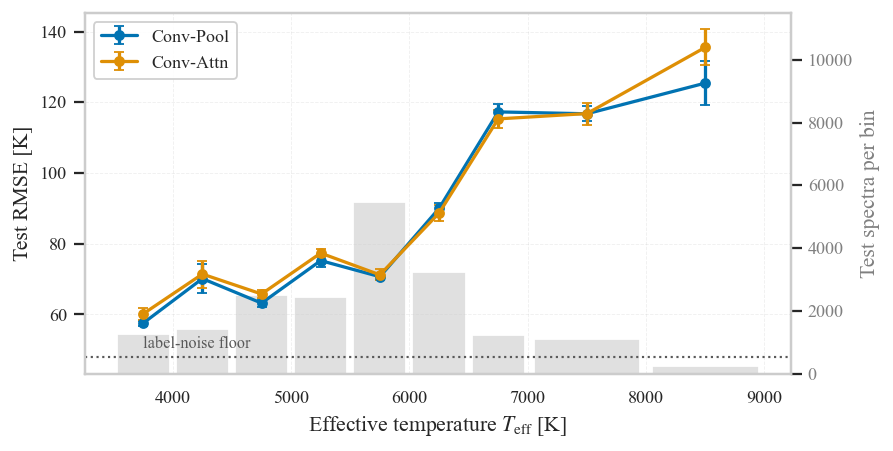

In [7]:
centres = np.array([np.mean([float(x) for x in r.strip('(] ').split(',')]) for r in order])
widths = np.array([np.diff([float(x) for x in r.strip('(] ').split(',')])[0] for r in order])

fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.6))

ax2 = ax.twinx()
ax2.bar(centres, tab['n'].values, width=widths * 0.9, color='0.88', zorder=1)
ax2.set_ylabel('Test spectra per bin', color='0.5')
ax2.tick_params(axis='y', labelcolor='0.5')
ax2.set_ylim(0, tab['n'].max() * 2.1)     # keep bars clear of the error curves
ax2.grid(False)

for m in MODELS:
    ax.errorbar(centres, tab[f'{m}_mean'].values, yerr=tab[f'{m}_std'].values,
                color=COLORS[m], marker='o', ms=5, lw=1.8, capsize=3,
                label=m, zorder=3)

ax.axhline(NOISE_FLOOR, color='0.35', ls=':', lw=1.2, zorder=2)
ax.text(centres[0], NOISE_FLOOR * 1.03, 'label-noise floor', fontsize=9, color='0.35', va='bottom')

ax.set_xlabel(r'Effective temperature $T_{\mathrm{eff}}$ [K]')
ax.set_ylabel('Test RMSE [K]')
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.grid(True, ls='--', alpha=0.3, lw=0.5)
ax.legend(loc='upper left', framealpha=0.92)
plt.tight_layout()
plt.show()

## 6. Diagnostic figure: prediction quality on the test set

Predictions pooled over the five seeds, so each panel holds five times the test set. A hexagonal density map is used rather than a scatter: at that count a scatter saturates and hides the very concentration it should display.

Conv-Pool: 94,490 pooled predictions
Conv-Attn: 94,490 pooled predictions


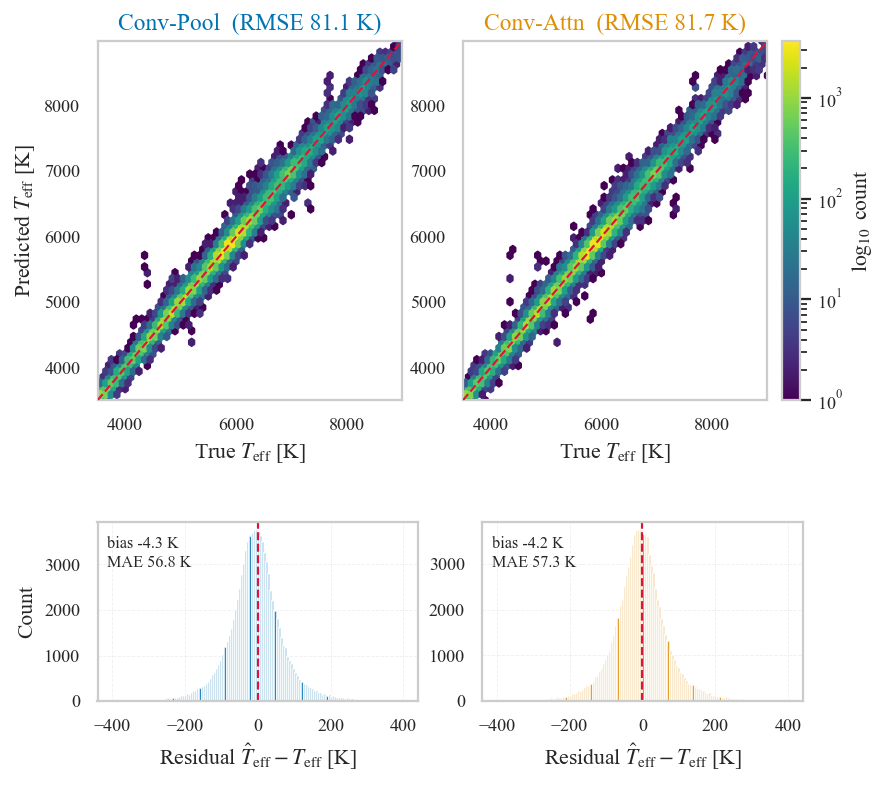

In [8]:
preds = {}
for m in MODELS:
    yt, yp = [], []
    for s in SEEDS:
        d = np.load(os.path.join(RESULTS_DIR, f'testpreds_{m}_seed{s}.npz'))
        yt.append(d['y_true_kelvin'])
        yp.append(d['y_pred_kelvin'])
    preds[m] = (np.concatenate(yt), np.concatenate(yp))
    print(f'{m}: {len(preds[m][0]):,} pooled predictions')

lo = min(preds[m][0].min() for m in MODELS)
hi = max(preds[m][0].max() for m in MODELS)

fig, axes = plt.subplots(2, 2, figsize=(W_DOUBLE, 6.6), gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.45})

for j, m in enumerate(MODELS):
    yt, yp = preds[m]
    resid = yp - yt

    ax = axes[0, j]
    hb = ax.hexbin(yt, yp, gridsize=55, bins='log', cmap='viridis', extent=(lo, hi, lo, hi), mincnt=1)
    ax.plot([lo, hi], [lo, hi], color='crimson', ls='--', lw=1.2, zorder=3)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(r'True $T_{\mathrm{eff}}$ [K]')
    if j == 0:
        ax.set_ylabel(r'Predicted $T_{\mathrm{eff}}$ [K]')
    ax.set_title(f'{m}  (RMSE {np.sqrt(np.mean(resid**2)):.1f} K)', color=COLORS[m])
    ax.grid(False)

    ax = axes[1, j]
    ax.hist(resid, bins=140, range=(-400, 400), color=COLORS[m], alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.2)
    ax.set_xlabel(r'Residual $\hat{T}_{\mathrm{eff}} - T_{\mathrm{eff}}$ [K]')
    if j == 0:
        ax.set_ylabel('Count')
    ax.text(0.03, 0.92,
            f'bias {resid.mean():+.1f} K\nMAE {np.abs(resid).mean():.1f} K',
            transform=ax.transAxes, va='top', fontsize=9)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

fig.colorbar(hb, ax=axes[0, :], label=r'$\log_{10}$ count', pad=0.02, fraction=0.03)
plt.show()

## 7. Summary of the training runs

The values computed above, collected in one table and in the sentences that report them, so that every number can be traced to this notebook rather than transcribed.

In [9]:
def fmt(metric, dec=2):
    r = tests.loc[metric]
    return (f"{r['Conv-Pool']:.{dec}f} $\\pm$ {r['Conv-Pool_sd']:.{dec}f}",
            f"{r['Conv-Attn']:.{dec}f} $\\pm$ {r['Conv-Attn_sd']:.{dec}f}",
            f"{r['t_p']:.3f}")

paper = pd.DataFrame([
    dict(zip(['Conv-Pool', 'Conv-Attn', 'p'], fmt('test_rmse_K'))),
    dict(zip(['Conv-Pool', 'Conv-Attn', 'p'], fmt('test_mae_K'))),
    dict(zip(['Conv-Pool', 'Conv-Attn', 'p'], fmt('test_r2', 4))),
    dict(zip(['Conv-Pool', 'Conv-Attn', 'p'], fmt('best_epoch', 1))),
    dict(zip(['Conv-Pool', 'Conv-Attn', 'p'], fmt('total_hours', 1))),
], index=['Test RMSE [K]', 'Test MAE [K]', r'Test $R^2$', 'Best epoch', 'Training time [h]'])

np_pool = runs.loc[runs.model == 'Conv-Pool', 'n_params'].iloc[0]
np_attn = runs.loc[runs.model == 'Conv-Attn', 'n_params'].iloc[0]
paper.insert(0, 'Parameters', [f'{np_pool:,} / {np_attn:,}'] + [''] * 4)

print('Training summary:')
display(paper)

print('\nLaTeX:')
print(paper.to_latex(escape=False))

# --- generated sentences ------------------------------------------------------
r = tests.loc['test_rmse_K']
ep = tests.loc['best_epoch']
th = tests.loc['total_hours']
mp = tests.loc['min_per_epoch']

print('=' * 74)
print('SUMMARY')
print('=' * 74)
print(f"""
At matched parameter budget ({np_pool:,} against {np_attn:,}, a difference of
{100 * abs(np_pool - np_attn) / max(np_pool, np_attn):.2f}%), the two architectures
reach indistinguishable accuracy on unperturbed spectra:
{r['Conv-Pool']:.2f} +/- {r['Conv-Pool_sd']:.2f} K against
{r['Conv-Attn']:.2f} +/- {r['Conv-Attn_sd']:.2f} K over five seeds
(paired t-test p = {r['t_p']:.2f}; 95% CI on the difference
[{r['ci_lo']:+.2f}, {r['ci_hi']:+.2f}] K). The clean baseline is therefore
equalised, and a divergence observed under perturbation is not a difference in
capacity or in clean accuracy.

Conv-Attn reaches that accuracy at {th['Conv-Attn'] / th['Conv-Pool']:.2f} times
the training cost, requiring {100 * (ep['Conv-Attn'] / ep['Conv-Pool'] - 1):.0f}%
more epochs to its optimum (p = {ep['t_p']:.3f}) and
{100 * (mp['Conv-Attn'] / mp['Conv-Pool'] - 1):.0f}% more time per epoch.

Both models sit within a factor of {noise['rmse_over_floor'].mean():.2f} of the
label-noise floor of {NOISE_FLOOR:.1f} K, which accounts for
{noise['label_share_of_mse_%'].mean():.0f}% of the mean squared error.
""")
print('=' * 74)
print(f'\nCheckpoints for Step 5 remain in {CKPT_DIR}/ '
      f'({n_ckpt} files); nothing here modifies them.')

Training summary:


,Parameters,Conv-Pool,Conv-Attn,p
Test RMSE [K],"537,857 / 540,161",81.07 $\pm$ 0.48,81.73 $\pm$ 0.62,0.143
Test MAE [K],,56.79 $\pm$ 0.41,57.32 $\pm$ 0.52,0.224
Test $R^2$,,0.9929 $\pm$ 0.0001,0.9928 $\pm$ 0.0001,0.143
Best epoch,,50.6 $\pm$ 4.5,63.6 $\pm$ 2.1,0.005
Training time [h],,0.8 $\pm$ 0.1,1.6 $\pm$ 0.1,0.000



LaTeX:
\begin{tabular}{lllll}
\toprule
 & Parameters & Conv-Pool & Conv-Attn & p \\
\midrule
Test RMSE [K] & 537,857 / 540,161 & 81.07 $\pm$ 0.48 & 81.73 $\pm$ 0.62 & 0.143 \\
Test MAE [K] &  & 56.79 $\pm$ 0.41 & 57.32 $\pm$ 0.52 & 0.224 \\
Test $R^2$ &  & 0.9929 $\pm$ 0.0001 & 0.9928 $\pm$ 0.0001 & 0.143 \\
Best epoch &  & 50.6 $\pm$ 4.5 & 63.6 $\pm$ 2.1 & 0.005 \\
Training time [h] &  & 0.8 $\pm$ 0.1 & 1.6 $\pm$ 0.1 & 0.000 \\
\bottomrule
\end{tabular}

SUMMARY

At matched parameter budget (537,857 against 540,161, a difference of
0.43%), the two architectures
reach indistinguishable accuracy on unperturbed spectra:
81.07 +/- 0.48 K against
81.73 +/- 0.62 K over five seeds
(paired t-test p = 0.14; 95% CI on the difference
[-0.34, +1.65] K). The clean baseline is therefore
equalised, and a divergence observed under perturbation is not a difference in
capacity or in clean accuracy.

Conv-Attn reaches that accuracy at 2.07 times
the training cost, requiring 26%
more epochs to its optim